In [1]:
import sys
import os

# Agregar el directorio padre al sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import os
from sklearn.preprocessing import StandardScaler
import sqlite3

import json

import mlp.promok_functions as pk
import mlp.promok_models_config as pkconfig
from mlp.dataframe_tracker import *

import cashia_core.data_channel.promok_datapipe_func as pkdp
import cashia_core.data_channel.pm_datapipeline as pmdp


from datetime import datetime

In [2]:
import sys, pandas as pd, numpy as np, sklearn
print(sys.executable)
print("pandas", pd.__version__)
print("numpy", np.__version__)
print("sklearn", sklearn.__version__)

c:\Users\juan_\.conda\envs\cashia_env\python.exe
pandas 1.5.3
numpy 1.26.0
sklearn 1.2.2


In [3]:
date_and_time = datetime.now()
# Convierte la fecha y hora en una cadena con el formato deseado
str_date_and_time = date_and_time.strftime("%Y:%m:%d:%H:%M")

print(str_date_and_time)

all_stats = pk.ModelsStats()
all_stats.base_stats

2026:11:05:19:49


dict_values(['05/11/2026 19:49:36', 'Undefined', 'Undefined', 'Undefined', 'Undefined', 'Unknown', 'Unknown', -1, -1, -1, -1.0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, None, -1, 'Unknown', 'Unknown', 'None', 'None', 'None'])

## 1 Lectura de datos de configuración

### 1.1 Datos categóricos

In [4]:
print('Configuration file: ', pkconfig.configuration_file_name)
all_features = pd.read_excel("./config/"+pkconfig.configuration_file_name, index_col=0)
features = all_features[all_features[pkconfig.conf_column] == 'Sí']

features_to_use = set(features['Característica'].values)
features_to_use

Configuration file:  CashIA_ConfFile.xlsx


c:\Users\juan_\.conda\envs\cashia_env\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


{'Ciclo',
 'Dependientes',
 'Edad Solicitud',
 'Egresos',
 'Frecuencia_Ant',
 'Genero',
 'Incobrable',
 'Ingresos',
 'Mes inicial',
 'Monto',
 'Monto_Ant',
 'Score Agt',
 'Score_Ant'}

In [5]:
categorical_features = set(features[(features['Tipo de dato'] == 'Categórico') & (features['Tipo de variable'] == 'Predictor')]['Característica'].values)
categorical_features

{'Genero'}

### 1.2 Datos cuantitativos

In [6]:
quantitative_features = set(features[(features['Tipo de dato'] == 'Cuantitativo') & (features['Tipo de variable'] == 'Predictor')]['Característica'].values)
quantitative_features

{'Ciclo',
 'Dependientes',
 'Edad Solicitud',
 'Egresos',
 'Frecuencia_Ant',
 'Ingresos',
 'Mes inicial',
 'Monto',
 'Monto_Ant',
 'Score Agt',
 'Score_Ant'}

In [7]:
monetary_features = features[features['Monetario'] == 1]['Característica']

### 1.3 Registro de las características de los datos en las estadísticas

In [8]:
categorical_list = list(categorical_features)
categorical_list.sort()

quantitative_list = list(quantitative_features)
quantitative_list.sort()

all_stats.base_stats.fields["Model"] = pkconfig.conf_column
all_stats.base_stats.fields["Features"] = json.dumps({"Categorical":categorical_list,"Quantitative":quantitative_list})
all_stats.base_stats.fields["Notes"] = pkconfig.notes
all_stats.base_stats.fields["SourceFile"] = pkconfig.data_file_name

In [9]:
all_stats.base_stats

dict_values(['05/11/2026 19:49:36', 'Undefined', 'Undefined', 'Undefined', 'Undefined', 'Unknown', 'Unknown', -1, -1, -1, -1.0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, None, -1, '{"Categorical": ["Genero"], "Quantitative": ["Ciclo", "Dependientes", "Edad Solicitud", "Egresos", "Frecuencia_Ant", "Ingresos", "Mes inicial", "Monto", "Monto_Ant", "Score Agt", "Score_Ant"]}', 'Unknown', "zip_digits = 4  Usando: standardizationSin remplazar campos vacios por 'Unknown'", 'Data Set Cashia EntrenamientoRNV_Agt_CSProcessed.csv', 'RNV_Agt_CS'])

## 2 Lectura de los datos de entrenamiento

In [10]:
print('Data file: ', pkconfig.data_file_name)
data = pd.read_csv("./data/"+pkconfig.data_file_name, parse_dates=['Fecha Inicial'], index_col=0, dayfirst=True)
# Convertir a entero el índice
data.index = data.index.astype(int)
# Ordenar el DataFrame por el índice de menor a mayor
data = data.sort_index()
# pkdp.print_sizes(data)
data_tracker = DataFrameEvolutionTracker(data)
data_tracker.to_dataframe()

Data file:  Data Set Cashia EntrenamientoRNV_Agt_CSProcessed.csv


,Step,Rows,Columns,Column Names
0,Initialization,63535,14,"[Fecha Inicial, Monto, Edad Solicitud, Genero,..."


### 2.1 Borramos la columna de 'Score' si está presente ya que es una variable 'Target' usada en otro contexto.

In [11]:
if 'Score' in data.columns:
    data = data.drop(columns=['Score'])

In [12]:
data.head()

,Fecha Inicial,Monto,Edad Solicitud,Genero,Dependientes,Ingresos,Egresos,Ciclo,Monto_Ant,Frecuencia_Ant,Incobrable,Score_Ant,Score Agt,Mes inicial
id_solicitud,,,,,,,,,,,,,,
63174,2023-01-11,5000,36,Femenino,0,9000,0,2,3000,1.291359,0,0.0,0.000000,1
64336,2023-03-10,5000,60,Masculino,0,10000,4000,6,10000,1.063798,0,0.0,0.204555,3
65632,2023-02-06,5000,46,Masculino,0,7000,0,2,3000,1.588014,1,0.0,0.000000,2
65751,2023-03-17,8000,42,Femenino,2,16000,4500,5,8000,1.279658,0,0.0,0.204552,3
66185,2022-12-30,9000,45,Femenino,0,8600,0,6,7000,1.001202,0,0.0,0.000000,12


### 2.2 solo tomamos los datos hasta la fecha indicada

In [13]:
print(data.shape)
data = data[(data['Fecha Inicial'] <= pkconfig.max_date) & (data['Fecha Inicial'] >= pkconfig.min_date)]
pkdp.print_sizes(data)
data_tracker.register_step("Filtered by date range", data)
data_tracker.to_dataframe()

(63535, 14)
Rows: 63450
Columns: 14
Max index: 264498


,Step,Rows,Columns,Column Names
0,Initialization,63535,14,"[Fecha Inicial, Monto, Edad Solicitud, Genero,..."
1,Filtered by date range,63450,14,"[Fecha Inicial, Monto, Edad Solicitud, Genero,..."


### 2.3 Registramos datos para las estadísticas

In [14]:
all_stats.base_stats.fields["Size"] = len(data)

## 4 Simplificación del CP a n cifras

In [15]:
if pkconfig.zip_digits <= 4:
    print("Simplificando CP")
    if 'CP' in features_to_use:
        # Guardamos el conjunto de CP para almacenarlos posteriormente en 
        # el campo data_parameters de un modelo
        training_cps = data[['CP']]
        training_cps = training_cps.drop_duplicates().reset_index(drop=True)
        
        pkdp.transform_CP(data,'CP', pkconfig.zip_digits)
        
    if 'CP Aval' in features_to_use:
        # Guardamos el conjunto de CP Aval para almacenarlos posteriormente en 
        # el campo data_parameters de un modelo
        training_cps_aval = data[['CP Aval']]
        training_cps_aval = training_cps_aval.drop_duplicates().reset_index(drop=True)
        training_cps_aval = training_cps_aval.rename(columns={'CP Aval':'CP'})
        
        pkdp.transform_CP(data,'CP Aval', pkconfig.zip_digits)

Simplificando CP


In [16]:
data[monetary_features].head()

,Monto,Ingresos,Egresos,Monto_Ant
id_solicitud,,,,
63174,5000,9000,0,3000
64336,5000,10000,4000,10000
65632,5000,7000,0,3000
65751,8000,16000,4500,8000
66372,7000,8000,0,5000


In [17]:
converter = pmdp.CurrentValueConverter(pkconfig.get_mlp_resource_key("inflation_table"))

In [18]:
for feature in monetary_features:
    data = converter.to_current_value(data, 'Fecha Inicial', feature)

In [19]:
data[monetary_features].head()

,Monto,Ingresos,Egresos,Monto_Ant
id_solicitud,,,,
63174,5714,10285,0,3428
64336,5667,11334,4533,11334
65632,5682,7955,0,3409
65751,9067,18135,5100,9067
66372,8000,9142,0,5714


In [20]:
#data.to_excel("ProcessedData2.xlsx")

In [21]:
converter_500 = pmdp.MultipleAdjuster(500)
data = converter_500.adjust_amount(data, 'Monto')

In [22]:
data[monetary_features].head()

,Monto,Ingresos,Egresos,Monto_Ant
id_solicitud,,,,
63174,6000,10285,0,3428
64336,6000,11334,4533,11334
65632,6000,7955,0,3409
65751,9500,18135,5100,9067
66372,8000,9142,0,5714


In [23]:
# Monto promedio de los "buenos pagadores"
good_payer = data[data['Incobrable']==0]
good_payer['Monto'].mean()

8896.776627856834

In [24]:
# Monto promedio de los "malos pagadores"
bad_payer = good_payer = data[data['Incobrable']==1]
bad_payer['Monto'].mean()

9019.859402460457

In [25]:
# Promedio de "Incobrabilidad"
data['Incobrable'].mean()

0.2690307328605201

In [26]:
# Promedio del monto de préstamo
data['Monto'].mean()

8929.889676910954

## 3 Feature engineering directly with sklearn

In [27]:
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OrdinalEncoder

predictors = data.drop(columns=['Incobrable', 'Fecha Inicial'])

target = data['Incobrable']

preprocessor = make_column_transformer(
    (
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=99999999),
        list(categorical_features),
    ),
    (StandardScaler(), list(quantitative_features)),
)


## 6 Run models

In [28]:
train_type = pk.BY_SIZE

In [29]:
if train_type == pk.BY_SIZE:

    
    totals = data["Incobrable"].value_counts()
    
    train_init_date = data.iloc[0]['Fecha Inicial']
    train_end_date = data.iloc[-1]['Fecha Inicial']
    
    data = data.drop('Fecha Inicial', axis=1)
    
    all_stats.base_stats.fields['Paid'] = int(totals[0])
    all_stats.base_stats.fields['Unpaid'] = int(totals[1])
    all_stats.base_stats.fields['AccMin'] = float(max(totals[0],totals[1])/(totals[0]+totals[1])*100)
    
    all_stats.base_stats.fields["TestSize"] = pkconfig.test_size
    models_tester = pk.ModelsTester(data, pkconfig.models_to_test, 
                                    pkconfig.test_size, split=pk.BY_SIZE)
    
elif train_type == pk.BY_INDEX:
    dates = data[['Fecha Inicial']]
    data = data.drop('Fecha Inicial', axis=1)
    
    data_size = data.shape[0]
    train_size = int(data_size/2)
    test_init = int(data_size*4/5)
    test_size = int(data_size/5)

    print("Data size: ", data_size)
    print("Train size: ", train_size)
    print("Test init: ", test_init)
    print("Test size: ", test_size)

    test_data = data.iloc[test_init:test_init+test_size]

    train_init_date = dates.loc[data.index[0],'Fecha Inicial']
    train_end_date = dates.loc[data.index[train_size],'Fecha Inicial']
    test_init_date = dates.loc[data.index[test_init],'Fecha Inicial']
    test_end_date = dates.loc[data.index[test_init+test_size-1],'Fecha Inicial']

    print("Evalueating with:")
    print(f"Train from: {train_init_date} to {train_end_date}")
    print(f"Test from: {test_init_date} to {test_end_date}")

    all_stats.base_stats.fields["TrainInitDate"] = str(train_init_date)
    all_stats.base_stats.fields["TrainEndDate"] = str(train_end_date)
    all_stats.base_stats.fields["TestInitDate"] = str(test_init_date)
    all_stats.base_stats.fields["TestEndDate" ] = str(test_end_date)

    all_stats.base_stats.fields["Size"] = len(test_data)

    totals = test_data["Incobrable"].value_counts()
    all_stats.base_stats.fields['Paid'] = int(totals[0])
    all_stats.base_stats.fields['Unpaid'] = int(totals[1])

    all_stats.base_stats.fields['AccMin'] = float(max(totals[0],totals[1])/(totals[0]+totals[1])*100)
    
    models_tester = pk.ModelsTester(data, pkconfig.models_to_test, pkconfig.test_size,
                                    train_init=0, train_size=train_size, test_init=test_init, 
                                    test_size=test_size, split=pk.BY_INDEX)
    all_stats.base_stats.fields["TestSize"] =  models_tester.x_test.shape[0]/models_tester.data.shape[0]
else:
    train_init_date = data.iloc[0]['Fecha Inicial']
    train_end_date = pd.to_datetime('2022-12-22')

    test_init_date = train_end_date + pd.Timedelta(days=1)
    test_end_date = pd.to_datetime('2023-03-22')
    
    print("Evalueating with:")
    print(f"Train from: {train_init_date} to {train_end_date}")
    print(f"Test from: {test_init_date} to {test_end_date}")
    
  
    all_stats.base_stats.fields["TrainInitDate"] = str(train_init_date)
    all_stats.base_stats.fields["TrainEndDate"] = str(train_end_date)
    all_stats.base_stats.fields["TestInitDate"] = str(test_init_date)
    all_stats.base_stats.fields["TestEndDate" ] = str(test_end_date)

    
    models_tester = pk.ModelsTester(data, pkconfig.models_to_test,  
                                    train_end_date=train_end_date,
                                    test_end_date=test_end_date,
                                    split=pk.BY_DATE)
    
    all_stats.base_stats.fields["TestSize"] = models_tester.x_test.shape[0]/models_tester.data.shape[0]
    all_stats.base_stats.fields["Size"] = models_tester.data.shape[0]

    totals = models_tester.y_test.value_counts()
    all_stats.base_stats.fields['Paid'] = int(totals[0])
    all_stats.base_stats.fields['Unpaid'] = int(totals[1])

    all_stats.base_stats.fields['AccMin'] = float(max(totals[0],totals[1])/(totals[0]+totals[1])*100)

In [30]:
data.shape

(63450, 13)

In [31]:
models_tester.x_train.columns

Index(['Monto', 'Edad Solicitud', 'Genero', 'Dependientes', 'Ingresos',
       'Egresos', 'Ciclo', 'Monto_Ant', 'Frecuencia_Ant', 'Score_Ant',
       'Score Agt', 'Mes inicial'],
      dtype='object')

In [32]:
all_columns = list(data.columns)
all_columns.sort()
all_columns

['Ciclo',
 'Dependientes',
 'Edad Solicitud',
 'Egresos',
 'Frecuencia_Ant',
 'Genero',
 'Incobrable',
 'Ingresos',
 'Mes inicial',
 'Monto',
 'Monto_Ant',
 'Score Agt',
 'Score_Ant']

### Correr los diferentes modelos (hacer el 'fit' con cada uno de ellos) con los datos de entrenamiento

In [33]:
models_tester.run_all_models(preprocessor)

Running: Random_Forest


### Correr los modelos con los datos de prueba y desplegar las estadísticas

********************* Results for model: Random_Forest : {'criterion': 'gini', 'bootstrap': True, 'random_state': 100} *********************
********************** TEST **********************
********************** TRAIN **********************
**************** Unbral para best accurracy *******************
Best threshold =  0.47000000000000003


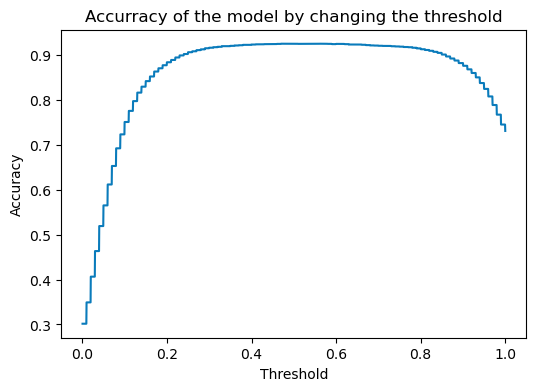

Pagados: 46380 Incobrables: 17070
Accuracy mínimo: 73.09692671394798
Tamaño del data set:  63450
Porcentaje de impagados: 26.9031
------Best accurracy threshold Test scores for Random_Forest------
Recall: 78.9982
Precision: 92.0792
F1-Score: 85.0386
Accuracy score: 92.5217
AUC Score: 88.2486
Accurracy Gain:  26.574
Monetary Gain:  $12,056,936
Reference Value:  $-2,955,204
Improvement:  508.0%
Model rejection rate 23.1%
False negative rate 7.3%


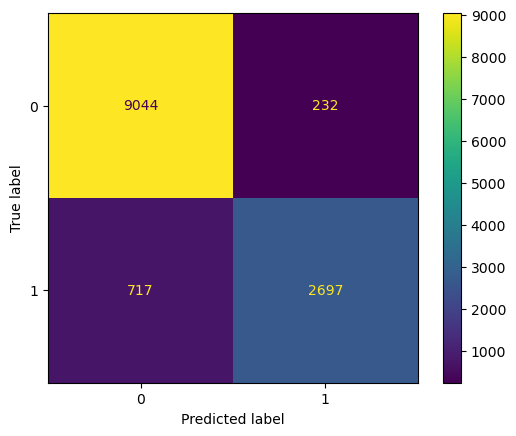

**************** Unbral para best monetary gain Test *******************
Best gain threshold =  0.47000000000000003


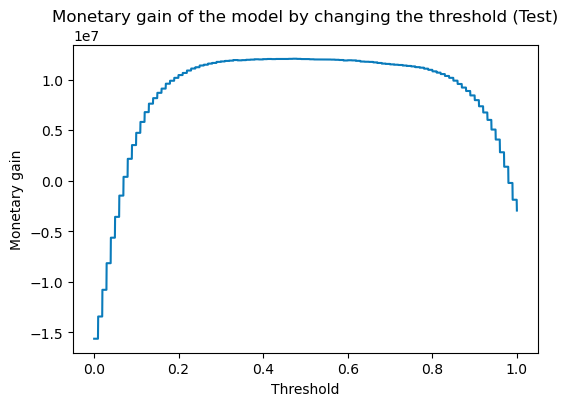

Model configuration:RNV_Agt_CS
Pagados: 46380 Incobrables: 17070
Accuracy mínimo: 73.09692671394798
Tamaño del data set:  63450
Porcentaje de impagados: 26.9031
------Best monetary gain threshold Test scores for Random_Forest------
Recall: 78.9982
Precision: 92.0792
F1-Score: 85.0386
Accuracy score: 92.5217
AUC Score: 88.2486
Accurracy Gain:  26.574
Monetary Gain:  $12,056,936
Reference Value:  $-2,955,204
Improvement:  508.0%
Model rejection rate 23.1%
False negative rate 7.3%


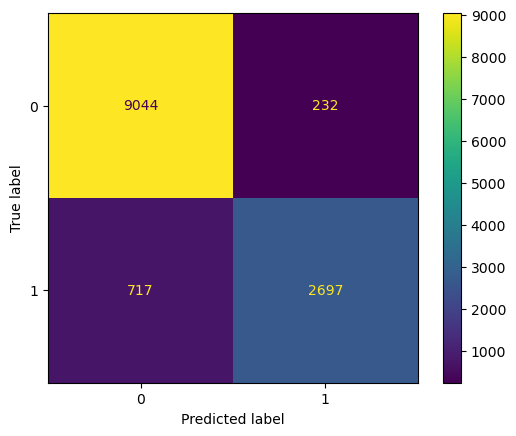

**************** Unbral para best monetary gain Train *******************
Best gain threshold =  0.49 with a monetary gain of 68525204.0


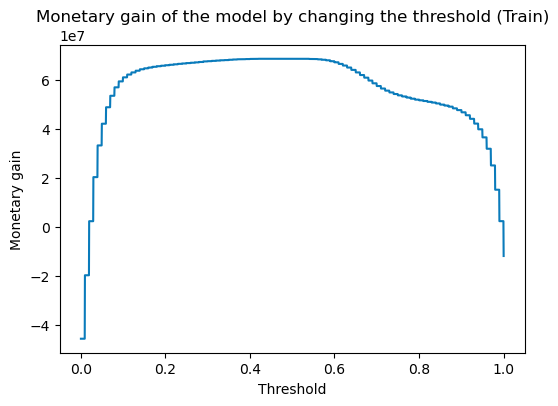

In [34]:
for model in models_tester.models:
    print(f"********************* Results for model: { model.name} : {model.parameters} *********************")
    print("********************** TEST **********************")
    y_pred_test = model.pipeline.predict(models_tester.x_test)
    all_stats.add_and_print_stats(models_tester.y_test, y_pred_test, model.name, model.parameters, "Test")

    print("********************** TRAIN **********************")
    y_pred_train = model.pipeline.predict(models_tester.x_train)
    all_stats.add_and_print_stats(models_tester.y_train, y_pred_train, model.name, model.parameters, "Train")
    
    #if (model.name != "Random Forest") and (model.name != "Ada Boost"):
    if (model.name != "Ada Boost"):
        ### Estadisticas con el mejor umbral para el accurracy y monetary gain

        predictions = model.pipeline.predict_proba(models_tester.x_test)[:,1]
        acceptance_threshold, accurracy_list, best_threshold, best_accurracy, gl, bgt, bg =  \
                                                                        pk.find_best_threshold(predictions, models_tester.y_test)
        model.best_gain_threshold = bgt
        model.best_accurracy_threshold = best_threshold
        
        print("**************** Unbral para best accurracy *******************")
        print("Best threshold = ", best_threshold)
        pk.plot_threshold_evolution(acceptance_threshold, accurracy_list, "Accurracy of the model by changing the threshold",
                                    "Threshold","Accuracy",
                                    f"{pkconfig.conf_column}_{model.name}_accuracy_test.png")
        y_pred_accuracy = np.where(predictions > best_threshold, 1, 0)
        all_stats.add_and_print_stats(models_tester.y_test, y_pred_accuracy, model.name, model.parameters, 
                                      "Best accurracy threshold Test", True,
                                      f"CM_{pkconfig.conf_column}_{model.name}_accuracy_test.png")

        ### Estadísticas de con la mejor ganancia monetária
        print("**************** Unbral para best monetary gain Test *******************")
        print("Best gain threshold = ", bgt)
        pk.plot_threshold_evolution(acceptance_threshold, gl, 
                                    "Monetary gain of the model by changing the threshold (Test)", 
                                    "Threshold", "Monetary gain",
                                    f"{pkconfig.conf_column}_{model.name}_best_gain_test.png")
        y_pred_monetary_test = np.where(predictions > bgt, 1, 0)
        print(f"Model configuration:{pkconfig.conf_column}")
        all_stats.add_and_print_stats(models_tester.y_test, y_pred_monetary_test, model.name, model.parameters, 
                                      "Best monetary gain threshold Test", True,
                                      f"CM_{pkconfig.conf_column}_{model.name}_monetary_test.png")

        ### Estadísticas con la mejor ganancia monetária datos de entrenamiento
        print("**************** Unbral para best monetary gain Train *******************")
        predictions = model.pipeline.predict_proba(models_tester.x_train)[:,1]
        acceptance_threshold, accurracy_list, best_threshold, best_accurracy, gl, bgt, bg = pk.find_best_threshold(predictions, models_tester.y_train)

        print("Best gain threshold = ", bgt, "with a monetary gain of", bg)
        pk.plot_threshold_evolution(acceptance_threshold, gl, "Monetary gain of the model by changing the threshold (Train)",
                                    "Threshold", "Monetary gain",
                                    f"{pkconfig.conf_column}_{model.name}_best_gain_train.png")

        y_pred_monetary_train = np.where(predictions > bgt, 1, 0)
        all_stats.add_and_print_stats(models_tester.y_train, y_pred_monetary_train, model.name, model.parameters,"Best monetary gain threshold Train")
    #model.min_max_stats = min_max_stats
    model.columns = models_tester.x_train.columns
    model.feature_engineering = pkconfig.feature_engineering
    model.features = all_features
    model.conf_column = pkconfig.conf_column
    model.data_parameters['zip_digits'] = pkconfig.zip_digits
    model.data_parameters['Training init date'] = train_init_date
    model.data_parameters['Trainig en date'] = train_end_date
    model.data_parameters['SourceFile'] = pkconfig.source_file_name
    model.data_parameters['Date'] = str_date_and_time
    if 'CP' in features_to_use:
        model.data_parameters['CP'] = training_cps
    if 'CP Aval' in features_to_use:
        model.data_parameters['CP Aval'] = training_cps_aval
    model.save_with_pickle()

In [35]:
for model in models_tester.models:
    print(model)
    print("=====================================")

Model name: Random_Forest
Feature engineering: standardization
Best gain threshold: 0.47000000000000003



# Write statistics

## Write to data base

In [36]:
con = sqlite3.connect("promocash_stats.db")
cur = con.cursor()
cur.executemany("INSERT INTO stats VALUES(?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)", all_stats.values)
con.commit()

### Leer de la base de datos para escribir las estadísticas en la base de datos

In [37]:
df = pd.read_sql_query("SELECT * FROM stats", con)
df

,Date,TrainInitDate,TrainEndtDate,testInitDate,TestEndDate,Method,Evaluation,Size,Paid,Unpaid,...,ReferenceValue,Improvement,RejectionRate,ConfusionMatrix,False,Fetures,Parameters,Notes,SourceFile,Model
0,24/04/2024 17:36:30,Undefined,Undefined,Undefined,Undefined,Random_Forest_SMOTE,Test,28779,23368,5411,...,2266390.0,0.179125,0.125956,[[4271 403]\n [ 760 322]],0.151063,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Valores Act Rech2NV_AgtProcessed.csv,NV_Agt
1,24/04/2024 17:36:30,Undefined,Undefined,Undefined,Undefined,Random_Forest_SMOTE,Train,28779,23368,5411,...,9055982.0,2.812708,0.188029,[[18694 0]\n [ 0 4329]],0.000000,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Valores Act Rech2NV_AgtProcessed.csv,NV_Agt
2,24/04/2024 17:36:30,Undefined,Undefined,Undefined,Undefined,Random_Forest_SMOTE,Best accurracy threshold Test,28779,23368,5411,...,2266390.0,0.216101,0.028318,[[4625 49]\n [ 968 114]],0.173073,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Valores Act Rech2NV_AgtProcessed.csv,NV_Agt
3,24/04/2024 17:36:30,Undefined,Undefined,Undefined,Undefined,Random_Forest_SMOTE,Best monetary gain threshold Test,28779,23368,5411,...,2266390.0,0.243064,0.066887,[[4495 179]\n [ 876 206]],0.163098,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Valores Act Rech2NV_AgtProcessed.csv,NV_Agt
4,24/04/2024 17:36:30,Undefined,Undefined,Undefined,Undefined,Random_Forest_SMOTE,Best monetary gain threshold Train,28779,23368,5411,...,9055982.0,2.812708,0.188029,[[18694 0]\n [ 0 4329]],0.000000,"{""Categorical"": [""CP"", ""Genero"", ""TipoZona"", ""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Valores Act Rech2NV_AgtProcessed.csv,NV_Agt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
840,05/11/2026 19:49:36,Undefined,Undefined,Undefined,Undefined,Random_Forest,Test,63450,46380,17070,...,-2955204.0,5.067766,0.228920,[[9055 221]\n [ 730 2684]],0.074604,"{""Categorical"": [""Genero""], ""Quantitative"": [""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Data Set Cashia EntrenamientoRNV_Agt_CSProcess...,RNV_Agt_CS
841,05/11/2026 19:49:36,Undefined,Undefined,Undefined,Undefined,Random_Forest,Train,63450,46380,17070,...,-11820816.0,6.796497,0.268991,[[37104 0]\n [ 2 13654]],0.000054,"{""Categorical"": [""Genero""], ""Quantitative"": [""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Data Set Cashia EntrenamientoRNV_Agt_CSProcess...,RNV_Agt_CS
842,05/11/2026 19:49:36,Undefined,Undefined,Undefined,Undefined,Random_Forest,Best accurracy threshold Test,63450,46380,17070,...,-2955204.0,5.079900,0.230812,[[9044 232]\n [ 717 2697]],0.073456,"{""Categorical"": [""Genero""], ""Quantitative"": [""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Data Set Cashia EntrenamientoRNV_Agt_CSProcess...,RNV_Agt_CS
843,05/11/2026 19:49:36,Undefined,Undefined,Undefined,Undefined,Random_Forest,Best monetary gain threshold Test,63450,46380,17070,...,-2955204.0,5.079900,0.230812,[[9044 232]\n [ 717 2697]],0.073456,"{""Categorical"": [""Genero""], ""Quantitative"": [""...","{""criterion"": ""gini"", ""bootstrap"": true, ""rand...",zip_digits = 4 Usando: standardizationSin rem...,Data Set Cashia EntrenamientoRNV_Agt_CSProcess...,RNV_Agt_CS


In [38]:
time_now = datetime.now()

format_date_hour = "%Y-%m-%d %H:%M:%S"
date_and_hour = time_now.strftime(format_date_hour)

# Imprimir la fecha y hora
print("Ended at:", date_and_hour)

Ended at: 2026-11-05 20:05:08


In [39]:
con.commit()
con.close()

In [40]:
df.index.name = 'index'
df.to_excel("./statistics/"+pkconfig.stats_file_name)

In [41]:
# Escribir el archivo de data tracking
data_tracker.to_dataframe().to_csv("./data/" + pkconfig.conf_column + "_data_tracking_train.csv")

In [42]:
test_result = models_tester.x_test.copy()
test_result["Prediction"] = y_pred_monetary_test
test_result["Incobrable"] = models_tester.y_test
test_result

,Monto,Edad Solicitud,Genero,Dependientes,Ingresos,Egresos,Ciclo,Monto_Ant,Frecuencia_Ant,Score_Ant,Score Agt,Mes inicial,Prediction,Incobrable
id_solicitud,,,,,,,,,,,,,,
198736,12500,44,Masculino,0,5228,1045,3,5228,1.063516,1.01204,0.625556,3,0,0
179979,7000,40,Masculino,1,9494,5274,2,5274,0.850813,0.89601,0.001685,12,1,1
106714,14500,34,Femenino,2,12256,2339,4,7799,1.202920,0.20454,0.205792,10,0,0
238709,12500,52,Femenino,0,0,5134,3,6161,1.730085,1.00000,1.061687,10,0,0
235439,16000,52,Femenino,1,8760,6183,7,9275,1.134082,1.01209,0.840401,9,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
226505,10500,34,Femenino,2,18802,8264,7,10330,1.277873,1.01341,0.821434,8,0,0
150932,5500,38,Femenino,1,9095,9095,2,3210,0.998102,0.91737,0.423861,7,0,0
94441,8000,32,Femenino,0,6325,4518,2,5647,1.202845,0.20455,0.000059,7,1,1


In [43]:
test_result.to_csv("./data/TestResult"+pkconfig.conf_column+".csv")

In [44]:
preprocessor.fit(models_tester.x_train)
x_test_processed = preprocessor.transform(models_tester.x_test)

# Crear DataFrame a partir de los datos transformados
x_test_transformed_df = pd.DataFrame(
    data=x_test_processed,
    columns=models_tester.x_test.columns
)

In [45]:
models_tester.x_test.columns

Index(['Monto', 'Edad Solicitud', 'Genero', 'Dependientes', 'Ingresos',
       'Egresos', 'Ciclo', 'Monto_Ant', 'Frecuencia_Ant', 'Score_Ant',
       'Score Agt', 'Mes inicial'],
      dtype='object')

In [46]:
x_test_processed[0]

array([ 1.        , -1.10965894, -0.95812863, -0.45176242,  0.52447023,
        0.89983206, -0.41832551, -0.32898505, -0.92713462,  0.86906801,
       -0.62297865,  0.33928402])

In [47]:
x_test_transformed_df["Prediccion"] = models_tester.y_test.to_numpy()

In [48]:
models_tester.y_test

id_solicitud
198736    0
179979    1
106714    0
238709    0
235439    0
         ..
226505    0
150932    0
94441     1
200885    0
216537    1
Name: Incobrable, Length: 12690, dtype: int64

In [49]:
x_test_transformed_df

,Monto,Edad Solicitud,Genero,Dependientes,Ingresos,Egresos,Ciclo,Monto_Ant,Frecuencia_Ant,Score_Ant,Score Agt,Mes inicial,Prediccion
0,1.0,-1.109659,-0.958129,-0.451762,0.524470,0.899832,-0.418326,-0.328985,-0.927135,0.869068,-0.622979,0.339284,0
1,1.0,-0.105497,1.602636,-0.439319,-1.222408,-0.489940,-0.868630,-0.750152,0.115106,0.581354,-0.021017,0.024448,1
2,0.0,-0.802403,1.033577,0.243703,-0.650895,1.405204,-0.123201,0.092182,1.157348,-1.133254,0.368719,-0.447805,0
3,0.0,-0.138739,1.033577,-0.199382,1.745665,0.899832,0.992837,-0.328985,-0.927135,0.839213,-1.360685,0.968955,0
4,0.0,0.110342,0.749048,0.642967,1.126049,1.784232,-0.268933,1.355684,0.115106,0.869192,-0.124590,0.968955,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12685,0.0,0.604469,0.464518,0.928348,1.072941,0.394461,0.035479,1.355684,1.157348,0.872465,1.292404,-0.447805,0
12686,0.0,0.801787,0.179989,-0.997639,-0.040290,-0.868968,-0.556810,-0.750152,0.115106,0.634319,-0.077319,-0.132969,0
12687,0.0,-0.285006,0.179989,-0.338421,-1.226963,-0.237254,-0.123358,-0.750152,-0.927135,-1.133229,-0.468185,-0.605223,1
12688,1.0,3.963153,-0.673599,-0.456361,0.351158,-0.363597,-0.096679,-0.328985,2.199589,0.844643,1.286619,-0.369096,0


In [50]:
time_now = datetime.now()

date_and_hour = time_now.strftime(format_date_hour)

# Imprimir la fecha y hora
print("Ended at:", date_and_hour)

Ended at: 2026-11-05 20:05:17


In [51]:
# Hacer un sonido
if sys.platform.startswith("win"):
    import winsound
    winsound.Beep(1000, 500)  # Frecuencia de 1000 Hz, duración de 500 ms
    winsound.Beep(500, 500) 
    winsound.Beep(1000, 500) 
else:
    print('\a')  # Hace un beep en algunos sistemas UNIX
    
print('Configuration : ', pkconfig.conf_column)

Configuration :  RNV_Agt_CS


In [52]:
len(x_test_transformed_df)

12690

In [53]:
models_tester.y_test

id_solicitud
198736    0
179979    1
106714    0
238709    0
235439    0
         ..
226505    0
150932    0
94441     1
200885    0
216537    1
Name: Incobrable, Length: 12690, dtype: int64

In [54]:

max_score_value = data['Score Agt'].max()
min_score_value = data['Score Agt'].min()
print("Min: ", min_score_value)
print("Max: ", max_score_value)

Min:  0.0
Max:  2.9026


In [55]:
n_groups = 100
bins = np.linspace(min_score_value, max_score_value, n_groups+1)
labels = list(range(1,n_groups+1))

In [56]:
bins

array([0.      , 0.029026, 0.058052, 0.087078, 0.116104, 0.14513 ,
       0.174156, 0.203182, 0.232208, 0.261234, 0.29026 , 0.319286,
       0.348312, 0.377338, 0.406364, 0.43539 , 0.464416, 0.493442,
       0.522468, 0.551494, 0.58052 , 0.609546, 0.638572, 0.667598,
       0.696624, 0.72565 , 0.754676, 0.783702, 0.812728, 0.841754,
       0.87078 , 0.899806, 0.928832, 0.957858, 0.986884, 1.01591 ,
       1.044936, 1.073962, 1.102988, 1.132014, 1.16104 , 1.190066,
       1.219092, 1.248118, 1.277144, 1.30617 , 1.335196, 1.364222,
       1.393248, 1.422274, 1.4513  , 1.480326, 1.509352, 1.538378,
       1.567404, 1.59643 , 1.625456, 1.654482, 1.683508, 1.712534,
       1.74156 , 1.770586, 1.799612, 1.828638, 1.857664, 1.88669 ,
       1.915716, 1.944742, 1.973768, 2.002794, 2.03182 , 2.060846,
       2.089872, 2.118898, 2.147924, 2.17695 , 2.205976, 2.235002,
       2.264028, 2.293054, 2.32208 , 2.351106, 2.380132, 2.409158,
       2.438184, 2.46721 , 2.496236, 2.525262, 2.554288, 2.583

In [57]:
# x_test_transformed_df['Group'] = pd.cut(models_tester.x_test['Score Agt'], bins, labels=labels)

groups = pd.cut(
    models_tester.x_test['Score Agt'].to_numpy(),  # sin índice
    bins=bins,
    labels=labels
)

x_test_transformed_df['Group'] = groups  # groups ya no tiene índice de pandas


In [58]:
intervals = [f"[{bins[i]:.3f}, {bins[i+1]:.3f}]" for i in range(0, n_groups)]

In [59]:
x_test_transformed_df

,Monto,Edad Solicitud,Genero,Dependientes,Ingresos,Egresos,Ciclo,Monto_Ant,Frecuencia_Ant,Score_Ant,Score Agt,Mes inicial,Prediccion,Group
0,1.0,-1.109659,-0.958129,-0.451762,0.524470,0.899832,-0.418326,-0.328985,-0.927135,0.869068,-0.622979,0.339284,0,22
1,1.0,-0.105497,1.602636,-0.439319,-1.222408,-0.489940,-0.868630,-0.750152,0.115106,0.581354,-0.021017,0.024448,1,1
2,0.0,-0.802403,1.033577,0.243703,-0.650895,1.405204,-0.123201,0.092182,1.157348,-1.133254,0.368719,-0.447805,0,8
3,0.0,-0.138739,1.033577,-0.199382,1.745665,0.899832,0.992837,-0.328985,-0.927135,0.839213,-1.360685,0.968955,0,37
4,0.0,0.110342,0.749048,0.642967,1.126049,1.784232,-0.268933,1.355684,0.115106,0.869192,-0.124590,0.968955,0,29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12685,0.0,0.604469,0.464518,0.928348,1.072941,0.394461,0.035479,1.355684,1.157348,0.872465,1.292404,-0.447805,0,29
12686,0.0,0.801787,0.179989,-0.997639,-0.040290,-0.868968,-0.556810,-0.750152,0.115106,0.634319,-0.077319,-0.132969,0,15
12687,0.0,-0.285006,0.179989,-0.338421,-1.226963,-0.237254,-0.123358,-0.750152,-0.927135,-1.133229,-0.468185,-0.605223,1,1
12688,1.0,3.963153,-0.673599,-0.456361,0.351158,-0.363597,-0.096679,-0.328985,2.199589,0.844643,1.286619,-0.369096,0,20


In [60]:
grouped_data_mean = x_test_transformed_df.groupby('Group').mean()
grouped_data_mean = grouped_data_mean.reset_index()

In [61]:
grouped_data_mean = grouped_data_mean.rename(columns={"Prediccion":'% Predicción de incobrables'})

In [62]:
grouped_data_mean.columns

Index(['Group', 'Monto', 'Edad Solicitud', 'Genero', 'Dependientes',
       'Ingresos', 'Egresos', 'Ciclo', 'Monto_Ant', 'Frecuencia_Ant',
       'Score_Ant', 'Score Agt', 'Mes inicial', '% Predicción de incobrables'],
      dtype='object')

<Axes: xlabel='Group', ylabel='% Predicción de incobrables'>

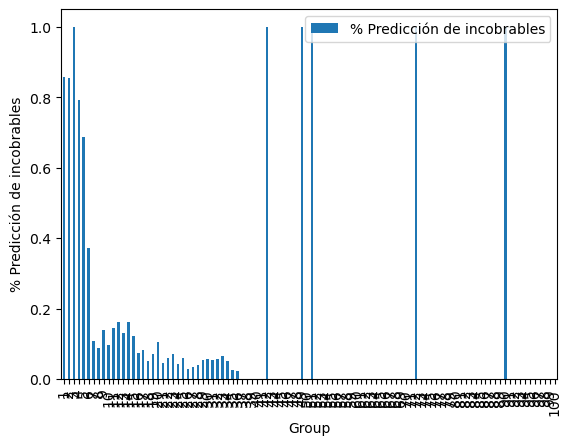

In [63]:
grouped_data_mean.plot.bar(x='Group', y='% Predicción de incobrables',  ylabel="% Predicción de incobrables",)

In [64]:
grouped_data_mean[['Group', '% Predicción de incobrables']]

,Group,% Predicción de incobrables
0,1,0.857040
1,2,0.856436
2,3,1.000000
3,4,0.791667
4,5,0.687500
...,...,...
95,96,NaN
96,97,NaN
97,98,NaN
98,99,NaN


In [65]:
grouped_data_count = x_test_transformed_df.groupby('Group').count()
grouped_data_count = grouped_data_count.reset_index()
grouped_data_count = grouped_data_count.rename(columns={'Prediccion':'No. de Créditos'})

In [66]:
grouped_data_count

,Group,Monto,Edad Solicitud,Genero,Dependientes,Ingresos,Egresos,Ciclo,Monto_Ant,Frecuencia_Ant,Score_Ant,Score Agt,Mes inicial,No. de Créditos
0,1,1392,1392,1392,1392,1392,1392,1392,1392,1392,1392,1392,1392,1392
1,2,202,202,202,202,202,202,202,202,202,202,202,202,202
2,3,34,34,34,34,34,34,34,34,34,34,34,34,34
3,4,24,24,24,24,24,24,24,24,24,24,24,24,24
4,5,16,16,16,16,16,16,16,16,16,16,16,16,16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,0,0,0,0,0,0,0,0,0,0,0,0,0
96,97,0,0,0,0,0,0,0,0,0,0,0,0,0
97,98,0,0,0,0,0,0,0,0,0,0,0,0,0
98,99,0,0,0,0,0,0,0,0,0,0,0,0,0


In [67]:
grouped_data_count[['Group','No. de Créditos']]

,Group,No. de Créditos
0,1,1392
1,2,202
2,3,34
3,4,24
4,5,16
...,...,...
95,96,0
96,97,0
97,98,0
98,99,0


<Axes: xlabel='Group', ylabel='No créditos'>

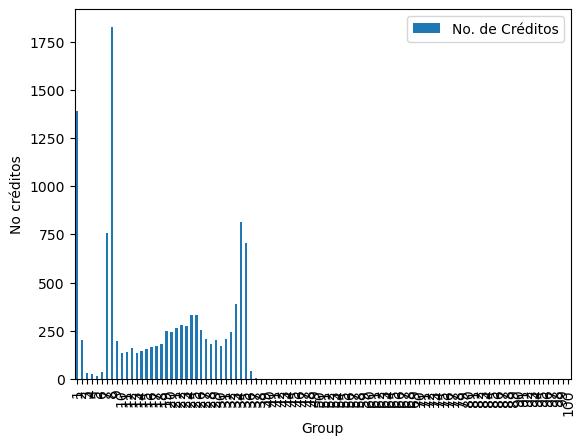

In [68]:
grouped_data_count.plot.bar(x='Group', y='No. de Créditos',  ylabel="No créditos",)

In [69]:
grouped_data_sum = x_test_transformed_df.groupby('Group').sum()
grouped_data_sum = grouped_data_sum.reset_index()
grouped_data_sum = grouped_data_sum.rename(columns={'Prediccion':'No. Créditos rechazados'})

In [70]:
grouped_data_sum[['Group','No. Créditos rechazados']]

,Group,No. Créditos rechazados
0,1,1193
1,2,173
2,3,34
3,4,19
4,5,11
...,...,...
95,96,0
96,97,0
97,98,0
98,99,0


In [71]:
grouped_data_sum['No. Créditos'] = grouped_data_count['No. de Créditos']

In [72]:
grouped_data_sum[['No. Créditos', 'No. Créditos rechazados']]

,No. Créditos,No. Créditos rechazados
0,1392,1193
1,202,173
2,34,34
3,24,19
4,16,11
...,...,...
95,0,0
96,0,0
97,0,0
98,0,0


In [73]:
grouped_data_sum['No Créditos aprobados'] = grouped_data_sum['No. Créditos'] - grouped_data_sum['No. Créditos rechazados']

In [74]:
grouped_data_sum[['Group','No. Créditos', 'No. Créditos rechazados', 'No Créditos aprobados']]

,Group,No. Créditos,No. Créditos rechazados,No Créditos aprobados
0,1,1392,1193,199
1,2,202,173,29
2,3,34,34,0
3,4,24,19,5
4,5,16,11,5
...,...,...,...,...
95,96,0,0,0
96,97,0,0,0
97,98,0,0,0
98,99,0,0,0


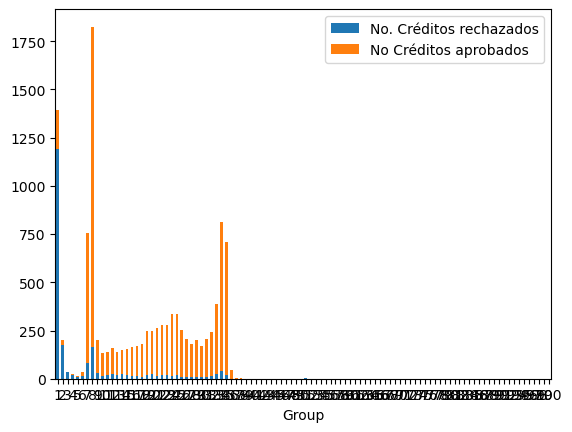

In [75]:
grouped_data_sum[['Group', 'No. Créditos rechazados', 'No Créditos aprobados']].plot.bar(x='Group', stacked=True, rot=0);

In [76]:
zoom_data = grouped_data_sum[(grouped_data_sum['Group']>=40) & (grouped_data_sum['Group']<=60)]

In [77]:
zoom_data[['Group','No. Créditos', 'No. Créditos rechazados', 'No Créditos aprobados']]

,Group,No. Créditos,No. Créditos rechazados,No Créditos aprobados
39,40,0,0,0
40,41,0,0,0
41,42,1,1,0
42,43,1,0,1
43,44,0,0,0
44,45,0,0,0
45,46,0,0,0
46,47,0,0,0
47,48,0,0,0
48,49,1,1,0


<Axes: xlabel='Group'>

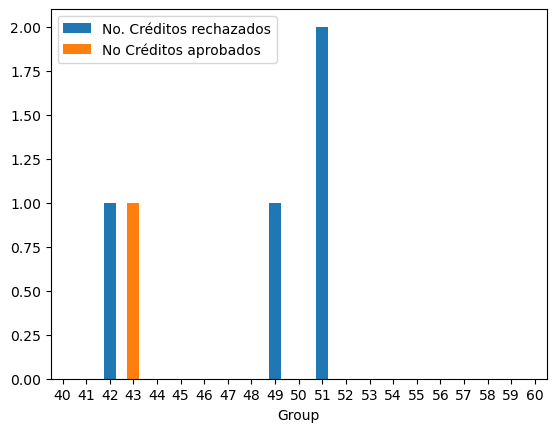

In [78]:
zoom_data[['Group', 'No. Créditos rechazados', 'No Créditos aprobados']].plot.bar(x='Group', stacked=True, rot=0)

In [79]:
#training_cps.to_excel("training_cps.xlsx")

In [80]:
data.head()

,Monto,Edad Solicitud,Genero,Dependientes,Ingresos,Egresos,Ciclo,Monto_Ant,Frecuencia_Ant,Incobrable,Score_Ant,Score Agt,Mes inicial
id_solicitud,,,,,,,,,,,,,
63174,6000,36,Femenino,0,10285,0,2,3428,1.291359,0,0.0,0.000000,1
64336,6000,60,Masculino,0,11334,4533,6,11334,1.063798,0,0.0,0.204555,3
65632,6000,46,Masculino,0,7955,0,2,3409,1.588014,1,0.0,0.000000,2
65751,9500,42,Femenino,2,18135,5100,5,9067,1.279658,0,0.0,0.204552,3
66372,8000,33,Femenino,0,9142,0,2,5714,1.386893,0,0.0,0.000000,1


In [81]:
list(data.columns).sort()

In [82]:
data.shape[0]

63450